Walmart Weekly Sales Prediction

Let's start by importing our data

In [1]:
import pandas as pd 
import numpy as np
import os 
os.getcwd()


'C:\\Users\\hamoud\\Documents\\Walmart_Weekly_Sales_Forecast'

In [2]:
test = pd.read_csv("./Data/test.csv")
sampleSubmission = pd.read_csv("./Data/sampleSubmission.csv")

In [3]:
test.head()

,Store,Dept,Date,IsHoliday
0,1,1,2012-11-02,False
1,1,1,2012-11-09,False
2,1,1,2012-11-16,False
3,1,1,2012-11-23,True
4,1,1,2012-11-30,False


In [4]:
sampleSubmission.head()

,Id,Weekly_Sales
0,1_1_2012-11-02,0
1,1_1_2012-11-09,0
2,1_1_2012-11-16,0
3,1_1_2012-11-23,0
4,1_1_2012-11-30,0


In [5]:
train = pd.read_csv("./Data/train.csv")
features = pd.read_csv("./Data/features.csv")
stores = pd.read_csv("./Data/stores.csv")

In [6]:
train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [7]:
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [8]:
stores.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


In [9]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  str    
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), str(1)
memory usage: 17.3 MB


In [10]:
features.info()

<class 'pandas.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         8190 non-null   int64  
 1   Date          8190 non-null   str    
 2   Temperature   8190 non-null   float64
 3   Fuel_Price    8190 non-null   float64
 4   MarkDown1     4032 non-null   float64
 5   MarkDown2     2921 non-null   float64
 6   MarkDown3     3613 non-null   float64
 7   MarkDown4     3464 non-null   float64
 8   MarkDown5     4050 non-null   float64
 9   CPI           7605 non-null   float64
 10  Unemployment  7605 non-null   float64
 11  IsHoliday     8190 non-null   bool   
dtypes: bool(1), float64(9), int64(1), str(1)
memory usage: 791.9 KB


In [11]:
stores.info()

<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Store   45 non-null     int64
 1   Type    45 non-null     str  
 2   Size    45 non-null     int64
dtypes: int64(2), str(1)
memory usage: 1.2 KB


We will start by doing the necessary merges:
merge stores and features based on Store column

In [12]:
feature_store_merged = features.merge(stores, how="inner",on = "Store")
feature_store_merged.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday,Type,Size
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False,A,151315
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True,A,151315
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False,A,151315
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False,A,151315
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False,A,151315


In [13]:
train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


Now, we can merge the training and testing dataset with the feature_store_merged on the Store/Date/IsHoliday Columns
Then we will sort the data  based on the Store, then the Departement and then the Date/Week.And finally we will 
reset the indexes

In [14]:
train_final_merged = train.merge(feature_store_merged, on = ["Store","Date","IsHoliday"])
train_final_merged = train_final_merged.sort_values(by= ["Store","Dept","Date"])
train_final_merged = train_final_merged.reset_index(drop=True)
train_final_merged.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315


In [15]:
test_final_merged = test.merge(feature_store_merged, how="inner", on = ["Store","Date","IsHoliday"])
test_final_merged = test_final_merged.sort_values(by= ["Store","Dept","Date"])
test_final_merged = test_final_merged.reset_index(drop=True)
test_final_merged.head()

,Store,Dept,Date,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2012-11-02,False,55.32,3.386,6766.44,5147.70,50.82,3639.90,2737.42,223.462779,6.573,A,151315
1,1,1,2012-11-09,False,61.24,3.314,11421.32,3370.89,40.28,4646.79,6154.16,223.481307,6.573,A,151315
2,1,1,2012-11-16,False,52.92,3.252,9696.28,292.10,103.78,1133.15,6612.69,223.512911,6.573,A,151315
3,1,1,2012-11-23,True,56.23,3.211,883.59,4.17,74910.32,209.91,303.32,223.561947,6.573,A,151315
4,1,1,2012-11-30,False,52.34,3.207,2460.03,NaN,3838.35,150.57,6966.34,223.610984,6.573,A,151315


In [16]:
test_final_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 115064 entries, 0 to 115063
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         115064 non-null  int64  
 1   Dept          115064 non-null  int64  
 2   Date          115064 non-null  str    
 3   IsHoliday     115064 non-null  bool   
 4   Temperature   115064 non-null  float64
 5   Fuel_Price    115064 non-null  float64
 6   MarkDown1     114915 non-null  float64
 7   MarkDown2     86437 non-null   float64
 8   MarkDown3     105235 non-null  float64
 9   MarkDown4     102176 non-null  float64
 10  MarkDown5     115064 non-null  float64
 11  CPI           76902 non-null   float64
 12  Unemployment  76902 non-null   float64
 13  Type          115064 non-null  str    
 14  Size          115064 non-null  int64  
dtypes: bool(1), float64(9), int64(3), str(2)
memory usage: 13.6 MB


***
Now, let's change the dtype of the Date coloumn to datetime in both sets, and create new data for them (year/month/day/week)
***

In [17]:
train_final_merged["Date"] = pd.to_datetime(train_final_merged["Date"])
train_final_merged["Date"]

0        2010-02-05
1        2010-02-12
2        2010-02-19
3        2010-02-26
4        2010-03-05
            ...    
421565   2012-09-28
421566   2012-10-05
421567   2012-10-12
421568   2012-10-19
421569   2012-10-26
Name: Date, Length: 421570, dtype: datetime64[us]

In [18]:
train_final_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[us]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
 5   Temperature   421570 non-null  float64       
 6   Fuel_Price    421570 non-null  float64       
 7   MarkDown1     150681 non-null  float64       
 8   MarkDown2     111248 non-null  float64       
 9   MarkDown3     137091 non-null  float64       
 10  MarkDown4     134967 non-null  float64       
 11  MarkDown5     151432 non-null  float64       
 12  CPI           421570 non-null  float64       
 13  Unemployment  421570 non-null  float64       
 14  Type          421570 non-null  str           
 15  Size          421570 non-nul

Now, let's add new columns from the Date Column, namely year,month,day and week of the year and week of the year.

In [19]:
train_final_merged["Year"] = train_final_merged["Date"].dt.year
train_final_merged["Month"] = train_final_merged["Date"].dt.month
train_final_merged["Day"] = train_final_merged["Date"].dt.day
train_final_merged["Week_Of_Year"] = train_final_merged["Date"].dt.isocalendar().week.astype(int)
train_final_merged["Week_Of_Month"] = ((train_final_merged["Date"].dt.day-1) // 7 + 1)


| Day   | After -1 | //7 |
| ----- | -------- | --- |
| 1–7   | 0–6      | 0   |
| 8–14  | 7–13     | 1   |
| 15–21 | 14–20    | 2   |
| 22–28 | 21–27    | 3   |
| 29–31 | 28–30    | 4   |


After we add 1

| Day   | WeekOfMonth |
| ----- | ----------- |
| 1–7   | 1           |
| 8–14  | 2           |
| 15–21 | 3           |
| 22–28 | 4           |
| 29–31 | 5           |


In [20]:
train_final_merged.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,MarkDown5,CPI,Unemployment,Type,Size,Year,Month,Day,Week_Of_Year,Week_Of_Month
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,...,NaN,211.096358,8.106,A,151315,2010,2,5,5,1
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,...,NaN,211.242170,8.106,A,151315,2010,2,12,6,2
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,...,NaN,211.289143,8.106,A,151315,2010,2,19,7,3
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,...,NaN,211.319643,8.106,A,151315,2010,2,26,8,4
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,...,NaN,211.350143,8.106,A,151315,2010,3,5,9,1


In [21]:
test_final_merged["Date"] = pd.to_datetime(test_final_merged["Date"])
test_final_merged["Date"]

0        2012-11-02
1        2012-11-09
2        2012-11-16
3        2012-11-23
4        2012-11-30
            ...    
115059   2013-06-28
115060   2013-07-05
115061   2013-07-12
115062   2013-07-19
115063   2013-07-26
Name: Date, Length: 115064, dtype: datetime64[us]

In [22]:
test_final_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 115064 entries, 0 to 115063
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         115064 non-null  int64         
 1   Dept          115064 non-null  int64         
 2   Date          115064 non-null  datetime64[us]
 3   IsHoliday     115064 non-null  bool          
 4   Temperature   115064 non-null  float64       
 5   Fuel_Price    115064 non-null  float64       
 6   MarkDown1     114915 non-null  float64       
 7   MarkDown2     86437 non-null   float64       
 8   MarkDown3     105235 non-null  float64       
 9   MarkDown4     102176 non-null  float64       
 10  MarkDown5     115064 non-null  float64       
 11  CPI           76902 non-null   float64       
 12  Unemployment  76902 non-null   float64       
 13  Type          115064 non-null  str           
 14  Size          115064 non-null  int64         
dtypes: bool(1), datetime64[us](1

In [23]:
test_final_merged["Year"] = test_final_merged["Date"].dt.year
test_final_merged["Month"] = test_final_merged["Date"].dt.month
test_final_merged["Day"] = test_final_merged["Date"].dt.day
test_final_merged["Week_Of_Year"] = test_final_merged["Date"].dt.isocalendar().week.astype(int)
test_final_merged["Week_Of_Month"] = ((test_final_merged["Date"].dt.day-1) // 7 + 1)

In [24]:
test_final_merged.head()

,Store,Dept,Date,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size,Year,Month,Day,Week_Of_Year,Week_Of_Month
0,1,1,2012-11-02,False,55.32,3.386,6766.44,5147.70,50.82,3639.90,2737.42,223.462779,6.573,A,151315,2012,11,2,44,1
1,1,1,2012-11-09,False,61.24,3.314,11421.32,3370.89,40.28,4646.79,6154.16,223.481307,6.573,A,151315,2012,11,9,45,2
2,1,1,2012-11-16,False,52.92,3.252,9696.28,292.10,103.78,1133.15,6612.69,223.512911,6.573,A,151315,2012,11,16,46,3
3,1,1,2012-11-23,True,56.23,3.211,883.59,4.17,74910.32,209.91,303.32,223.561947,6.573,A,151315,2012,11,23,47,4
4,1,1,2012-11-30,False,52.34,3.207,2460.03,NaN,3838.35,150.57,6966.34,223.610984,6.573,A,151315,2012,11,30,48,5


In [25]:
test_final_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 115064 entries, 0 to 115063
Data columns (total 20 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Store          115064 non-null  int64         
 1   Dept           115064 non-null  int64         
 2   Date           115064 non-null  datetime64[us]
 3   IsHoliday      115064 non-null  bool          
 4   Temperature    115064 non-null  float64       
 5   Fuel_Price     115064 non-null  float64       
 6   MarkDown1      114915 non-null  float64       
 7   MarkDown2      86437 non-null   float64       
 8   MarkDown3      105235 non-null  float64       
 9   MarkDown4      102176 non-null  float64       
 10  MarkDown5      115064 non-null  float64       
 11  CPI            76902 non-null   float64       
 12  Unemployment   76902 non-null   float64       
 13  Type           115064 non-null  str           
 14  Size           115064 non-null  int64         
 15  Year       

***
EDA
***

In [26]:
train_final_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 21 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Store          421570 non-null  int64         
 1   Dept           421570 non-null  int64         
 2   Date           421570 non-null  datetime64[us]
 3   Weekly_Sales   421570 non-null  float64       
 4   IsHoliday      421570 non-null  bool          
 5   Temperature    421570 non-null  float64       
 6   Fuel_Price     421570 non-null  float64       
 7   MarkDown1      150681 non-null  float64       
 8   MarkDown2      111248 non-null  float64       
 9   MarkDown3      137091 non-null  float64       
 10  MarkDown4      134967 non-null  float64       
 11  MarkDown5      151432 non-null  float64       
 12  CPI            421570 non-null  float64       
 13  Unemployment   421570 non-null  float64       
 14  Type           421570 non-null  str           
 15  Size       

In [27]:
train_final_merged.describe()

,Store,Dept,Date,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size,Year,Month,Day,Week_Of_Year,Week_Of_Month
count,421570.000000,421570.000000,421570,421570.000000,421570.000000,421570.000000,150681.000000,111248.000000,137091.000000,134967.000000,151432.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,2011-06-18 08:30:31.963375,15981.258123,60.090059,3.361027,7246.420196,3334.628621,1439.421384,3383.168256,4628.975079,171.201947,7.960289,136727.915739,2010.968591,6.449510,15.673131,25.826762,2.691691
min,1.000000,1.000000,2010-02-05 00:00:00,-4988.940000,-2.060000,2.472000,0.270000,-265.760000,-29.100000,0.220000,135.160000,126.064000,3.879000,34875.000000,2010.000000,1.000000,1.000000,1.000000,1.000000
25%,11.000000,18.000000,2010-10-08 00:00:00,2079.650000,46.680000,2.933000,2240.270000,41.600000,5.080000,504.220000,1878.440000,132.022667,6.891000,93638.000000,2010.000000,4.000000,8.000000,14.000000,2.000000
50%,22.000000,37.000000,2011-06-17 00:00:00,7612.030000,62.090000,3.452000,5347.450000,192.000000,24.600000,1481.310000,3359.450000,182.318780,7.866000,140167.000000,2011.000000,6.000000,16.000000,26.000000,3.000000
75%,33.000000,74.000000,2012-02-24 00:00:00,20205.852500,74.280000,3.738000,9210.900000,1926.940000,103.990000,3595.040000,5563.800000,212.416993,8.572000,202505.000000,2012.000000,9.000000,23.000000,38.000000,4.000000
max,45.000000,99.000000,2012-10-26 00:00:00,693099.360000,100.140000,4.468000,88646.760000,104519.540000,141630.610000,67474.850000,108519.280000,227.232807,14.313000,219622.000000,2012.000000,12.000000,31.000000,52.000000,5.000000
std,12.785297,30.492054,NaN,22711.183519,18.447931,0.458515,8291.221345,9475.357325,9623.078290,6292.384031,5962.887455,39.159276,1.863296,60980.583328,0.796876,3.243217,8.753549,14.151887,1.263852


Let's make some plots to understand our data better;

We start by plotting all stores total weekly sales

In [28]:
total_weekly_sales = train_final_merged.groupby('Week_Of_Year', as_index=False)["Weekly_Sales"].sum()
total_weekly_sales.head()

,Week_Of_Year,Weekly_Sales
0,1,8.773121e+07
1,2,8.269676e+07
2,3,8.273564e+07
3,4,7.943483e+07
4,5,1.419895e+08


In [29]:
import plotly.express as px

fig = px.line(
    total_weekly_sales,
    x="Week_Of_Year",
    y="Weekly_Sales",
    title="Total Walmart Stores Sales by Weeks of the Year",
    labels={
        "Week_Of_Year": "Week of the Year",
        "Weekly_Sales": "Total Weekly Sales ($)"
    },
)

fig.update_traces(
    hovertemplate="Week %{x}<br>Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x",
    width=800,
    height=500,
    title_x = 0.5
)

fig.show()


We can see that sales peak in week 7, 14, 22, 27, 40, 47 and 51 and drop really low at weeks 44, 48 and 52

Now we plot average store sales per week

In [30]:
weekly_store_sales = (train_final_merged.groupby(["Week_Of_Year", "Store"], as_index=False)["Weekly_Sales"].sum())
weekly_store_sales.head()


,Week_Of_Year,Store,Weekly_Sales
0,1,1,2995102.20
1,1,2,3557570.93
2,1,3,776419.55
3,1,4,3910242.34
4,1,5,598425.97


In [31]:
avg_store_sales = (weekly_store_sales.groupby("Week_Of_Year", as_index=False)["Weekly_Sales"].mean())
avg_store_sales.head()

,Week_Of_Year,Weekly_Sales
0,1,1.949582e+06
1,2,1.837706e+06
2,3,1.838570e+06
3,4,1.765218e+06
4,5,3.155321e+06


In [32]:
import plotly.express as px

fig = px.line(
    avg_store_sales,
    x="Week_Of_Year",
    y="Weekly_Sales",
    title="Average Walmart Store Sales by Week of Year",
    labels={
        "Week_Of_Year": "Week of the Year",
        "Weekly_Sales": "Average Weekly Store Sales ($)"
    },
)

fig.update_traces(
    hovertemplate="Week %{x}<br>Avg Store Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x",
    width=1000,
    height=500,
    title_x=0.5
)

fig.show()


Now lets see if total sales increase or decrease from 2010 to 2012

In [33]:
yearly_sales = (train_final_merged.groupby("Year")["Weekly_Sales"].sum().reset_index())
yearly_sales.head()

,Year,Weekly_Sales
0,2010,2.288886e+09
1,2011,2.448200e+09
2,2012,2.000133e+09


In [34]:
fig = px.line(yearly_sales, 
              x="Year", 
              y="Weekly_Sales", 
              title="Walmart Total Sales Trend by Year (2010-2012)",
              labels={
                    "Year": "Year",
                    "Weekly_Sales": "Total Sales ($)"
                    },)

fig.update_traces(
    hovertemplate="Year: %{x}<br>Total Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x",
    width=1000,
    height=500,
    title_x=0.5
)


At first sight, sales increase from 2010 to 2011 (≈ +160M$) and then drop heavily in 2012 (≈ -450M$).

**But this is a data coverage effect, not a real drop:** the data runs from 2010-02-05 to 2012-10-26, so each year has a different number of weeks (2010: 48, 2011: 52, 2012: 43), and 2012 is missing its November–December peak.

Comparing only the **39 weeks present in all three years** (ISO weeks 5 to 43), total sales are actually **stable**: 1,797M$ in 2010, 1,786M$ in 2011 and 1,831M$ in 2012 (+2.5%). Comparing the same weeks year-over-year (the "Sales by Year" plot below) is the fair comparison.

Now let's plot the sales of each store type (A,B,C) over 3 years

In [35]:
type_sales = (train_final_merged.groupby(["Week_Of_Year","Type"])["Weekly_Sales"].sum().reset_index())
type_sales.head()

,Week_Of_Year,Type,Weekly_Sales
0,1,A,56214517.08
1,1,B,25517191.19
2,1,C,5999501.45
3,2,A,53389134.89
4,2,B,23382012.79


In [36]:
fig = px.line(type_sales, 
              x="Week_Of_Year", 
              y="Weekly_Sales", 
              title="Sales by Week Over the Year for each Store Type",
              color= "Type",
              labels={
                    "Week_Of_Year": "Week of the Year",
                    "Weekly_Sales": "Total Sales ($)"
                    },)

fig.update_traces(
    hovertemplate="Week: %{x}<br>Total Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x",
    width=1000,
    height=500,
    title_x=0.5
)


We observe that Type C stores show relatively stable, linear sales throughout the year, whereas Type A and B stores display similar seasonal patterns: 

Their sales rise sharply around week 4, peak even more strongly at week 51, and then drop significantly in weeks 52 and 43.


Let's see the effect of Holidays on the weekly sales:

In [37]:
week_counts = (
    train_final_merged[["Date", "IsHoliday"]]
    .drop_duplicates()
    .groupby("IsHoliday")
    .size()
)

week_counts

IsHoliday
False    133
True      10
dtype: int64

In [38]:
holiday_effect = (train_final_merged.groupby("IsHoliday", as_index=False)["Weekly_Sales"].mean())
holiday_effect

,IsHoliday,Weekly_Sales
0,False,15901.445069
1,True,17035.823187


In [39]:
fig = px.bar(
    holiday_effect,
    x="IsHoliday",
    y="Weekly_Sales",
    title="Impact of Holidays on Weekly Sales",
    labels={
        "IsHoliday": "Week Type",
        "Weekly_Sales": "Average Weekly Sales ($)"
    },
    text_auto=".2s"
)

fig.update_traces(
    hovertemplate="%{x}<br>Avg Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    width=600,
    height=450,
    title_x=0.5
)

fig.show()


Holiday weeks generate higher sales than non-holiday weeks.
On average, weekly sales during holidays (17,035) are higher than during non-holiday weeks (15,901).

(17035.823187 − 15901.445069) / 15901.445069 × 100 = 7.13%

Even though holiday weeks are rare (10 out of 143), they still boost sales by approximately 7% compared to regular weeks, which represents a substantial impact on revenue for Walmart.



Markdowns and sales

In [40]:
markdown_cols = ["MarkDown1","MarkDown2","MarkDown3","MarkDown4","MarkDown5"]

weekly_markdown_sales = (
    train_final_merged
    .groupby("Week_Of_Year", as_index=False)
    .agg({
        "Weekly_Sales": "sum",
        **{c: "sum" for c in markdown_cols}
    })
)

weekly_markdown_sales["Total_MarkDown"] = (
    weekly_markdown_sales[markdown_cols].sum(axis=1)
)


In [41]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=weekly_markdown_sales["Week_Of_Year"],
    y=weekly_markdown_sales["Weekly_Sales"],
    name="Total Sales",
    yaxis="y1",
    line=dict(width=3)
))

fig.add_trace(go.Scatter(
    x=weekly_markdown_sales["Week_Of_Year"],
    y=weekly_markdown_sales["Total_MarkDown"],
    name="Total MarkDown",
    yaxis="y2",
    line=dict(width=3, dash="dot")
))

fig.update_layout(
    title="Total Sales vs Total MarkDowns by Week of Year",
    title_x=0.5,
    xaxis_title="Week of Year",
    yaxis=dict(title="Total Sales ($)"),
    yaxis2=dict(
        title="Total MarkDown ($)",
        overlaying="y",
        side="right"
    ),
    template="plotly_white",
    hovermode="x",
    width=1000,
    height=500
)

fig.show()


Let's see that in more details

In [42]:
markdown_cols = ["MarkDown1","MarkDown2","MarkDown3","MarkDown4","MarkDown5"]

weekly_markdown_sales = (
    train_final_merged
    .groupby("Week_Of_Year", as_index=False)
    .agg({
        "Weekly_Sales": "sum",
        **{c: "sum" for c in markdown_cols}
    })
)


In [43]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=weekly_markdown_sales["Week_Of_Year"],
    y=weekly_markdown_sales["Weekly_Sales"],
    name="Total Sales",
    yaxis="y1",
    line=dict(width=4)
))

for md in markdown_cols:
    fig.add_trace(go.Scatter(
        x=weekly_markdown_sales["Week_Of_Year"],
        y=weekly_markdown_sales[md],
        name=md,
        yaxis="y2",
        line=dict(width=2, dash="dot")
    ))

fig.update_layout(
    title="Weekly Sales vs MarkDown Campaigns",
    title_x=0.5,
    xaxis_title="Week of the Year",

    yaxis=dict(
        title="Total Sales ($)",
        showgrid=True
    ),

    yaxis2=dict(
        title="MarkDown Amount ($)",
        overlaying="y",
        side="right",
        showgrid=False
    ),

    template="plotly_white",
    hovermode="x",
    width=1100,
    height=550
)

fig.show()


We can see that when Markdowns spike, the sales also spike  at the same time or just right after

Let's plot the year to year sales differances:

In [44]:
sales_year_week = (
    train_final_merged
    .groupby(["Year", "Week_Of_Year"], as_index=False)["Weekly_Sales"]
    .sum()
)


In [45]:
import plotly.express as px

fig = px.line(
    sales_year_week,
    x="Week_Of_Year",
    y="Weekly_Sales",
    color="Year",
    title="Walmart Weekly Sales by Year",
    labels={
        "Week_Of_Year": "Week of Year",
        "Weekly_Sales": "Total Weekly Sales ($)"
    }
)

fig.update_traces(
    hovertemplate="Year %{Year}<br>Week %{x}<br>Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified",
    width=1100,
    height=550,
    title_x=0.5
)

fig.show()


Correlation matrix:

Let's make a correlation matrix to understand better the relationships between attributes

But first, we need to fid Nan in Markdowns with a 0, since it means there was no promotion


In [46]:
markdown_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]

train_final_merged[markdown_cols] = train_final_merged[markdown_cols].fillna(0)
test_final_merged[markdown_cols] = test_final_merged[markdown_cols].fillna(0)


In [47]:
train_final_merged.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,MarkDown5,CPI,Unemployment,Type,Size,Year,Month,Day,Week_Of_Year,Week_Of_Month
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,...,0.0,211.096358,8.106,A,151315,2010,2,5,5,1
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,...,0.0,211.242170,8.106,A,151315,2010,2,12,6,2
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,...,0.0,211.289143,8.106,A,151315,2010,2,19,7,3
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,...,0.0,211.319643,8.106,A,151315,2010,2,26,8,4
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,...,0.0,211.350143,8.106,A,151315,2010,3,5,9,1


In [48]:
numeric_cols = train_final_merged.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()
corr_matrix["Weekly_Sales"]

Store           -0.085195
Dept             0.148032
Weekly_Sales     1.000000
Temperature     -0.002312
Fuel_Price      -0.000120
MarkDown1        0.047172
MarkDown2        0.020716
MarkDown3        0.038562
MarkDown4        0.037467
MarkDown5        0.050465
CPI             -0.020921
Unemployment    -0.025864
Size             0.243828
Year            -0.010111
Month            0.028409
Day             -0.006187
Week_Of_Year     0.027673
Week_Of_Month   -0.004004
Name: Weekly_Sales, dtype: float64

In [49]:
fig = px.imshow(
    corr_matrix,
    text_auto="0.2f",
    aspect="auto",
    color_continuous_scale="RdBu",
    title="Correlation Matrix of Walmart Features"
)

fig.update_layout(
    width=1000,
    height=900,
    title_x=0.5
)

fig.show()


This correlation between attributes shows that store characteristics, dominate Walmart sales far more than external economic or weather factors. The strongest relationship with weekly sales is store size (0.24), confirming that larger stores consistently generate higher revenue regardless of timing or conditions. Department (0.15) is also highly influential, reflecting the fact that different product categories (e.g., groceries, electronics, clothing) naturally operate at very different sales scales. Promotional activity has a clear positive impact: all MarkDown variables have positive correlations (around 0.02–0.05), indicating that when Walmart runs discounts or special offers, sales reliably increase, even though the effect varies by promotion type. In contrast, macroeconomic and environmental variables such as temperature, fuel price, CPI, and unemployment show almost no correlation, suggesting that Walmart’s weekly demand is very stable and not strongly affected by short-term economic or weather fluctuations.

Now, let's add some meaningfull data: 

We will add labor day week, thanksgiving week, chrismas week, super bowl


In [50]:

THANKSGIVING_WEEK = {
    2010: pd.Timestamp("2010-11-26"),
    2011: pd.Timestamp("2011-11-25"),
    2012: pd.Timestamp("2012-11-23"),
    2013: pd.Timestamp("2013-11-29"),  
}

CHRISTMAS_WEEK = {
    2010: pd.Timestamp("2010-12-31"),
    2011: pd.Timestamp("2011-12-30"),
    2012: pd.Timestamp("2012-12-28"),
    2013: pd.Timestamp("2013-12-27"),  
}

SUPER_BOWL_WEEK = {
    2010: pd.Timestamp("2010-02-12"),
    2011: pd.Timestamp("2011-02-11"),
    2012: pd.Timestamp("2012-02-10"),
    2013: pd.Timestamp("2013-02-08"),  
}

LABOR_DAY_WEEK = {
    2010: pd.Timestamp("2010-09-10"),
    2011: pd.Timestamp("2011-09-09"),
    2012: pd.Timestamp("2012-09-07"),
    2013: pd.Timestamp("2013-09-06"),  
}

In [51]:
def add_days_to_holidays(df):
    df = df.copy()
    df["Days_to_Thanksgiving"] = df["Date"].apply(lambda d: (THANKSGIVING_WEEK[d.year] - d).days).astype(int)
    df["Days_to_Christmas"]    = df["Date"].apply(lambda d: (CHRISTMAS_WEEK[d.year] - d).days).astype(int)
    df["Days_to_SuperBowl"]     = df["Date"].apply(lambda d: (SUPER_BOWL_WEEK[d.year] - d).days).astype(int)
    df["Days_to_LaborDay"]      = df["Date"].apply(lambda d: (LABOR_DAY_WEEK[d.year] - d).days).astype(int)
    return df

In [52]:
train_final_merged = add_days_to_holidays(train_final_merged)
test_final_merged  = add_days_to_holidays(test_final_merged)


In [53]:
train_final_merged[["Date","Days_to_SuperBowl","Days_to_LaborDay","Days_to_Thanksgiving","Days_to_Christmas"]].head()

,Date,Days_to_SuperBowl,Days_to_LaborDay,Days_to_Thanksgiving,Days_to_Christmas
0,2010-02-05,7,217,294,329
1,2010-02-12,0,210,287,322
2,2010-02-19,-7,203,280,315
3,2010-02-26,-14,196,273,308
4,2010-03-05,-21,189,266,301


let's see the correlation matrix of features on the weekly sales columnsagain:

In [54]:
numeric_cols = train_final_merged.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()
corr_matrix["Weekly_Sales"]

Store                  -0.085195
Dept                    0.148032
Weekly_Sales            1.000000
Temperature            -0.002312
Fuel_Price             -0.000120
MarkDown1               0.047172
MarkDown2               0.020716
MarkDown3               0.038562
MarkDown4               0.037467
MarkDown5               0.050465
CPI                    -0.020921
Unemployment           -0.025864
Size                    0.243828
Year                   -0.010111
Month                   0.028409
Day                    -0.006187
Week_Of_Year            0.027673
Week_Of_Month          -0.004004
Days_to_Thanksgiving   -0.027673
Days_to_Christmas      -0.027673
Days_to_SuperBowl      -0.027673
Days_to_LaborDay       -0.027673
Name: Weekly_Sales, dtype: float64

In [55]:
fig = px.imshow(
    corr_matrix,
    text_auto="0.2f",
    aspect="auto",
    color_continuous_scale="Jet",
    title="Correlation Matrix of Walmart Features"
)

fig.update_layout(
    width=1000,
    height=900,
    title_x=0.5
)

fig.show()

In [56]:
train_final_merged.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,Size,Year,Month,Day,Week_Of_Year,Week_Of_Month,Days_to_Thanksgiving,Days_to_Christmas,Days_to_SuperBowl,Days_to_LaborDay
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,...,151315,2010,2,5,5,1,294,329,7,217
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,...,151315,2010,2,12,6,2,287,322,0,210
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,...,151315,2010,2,19,7,3,280,315,-7,203
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,...,151315,2010,2,26,8,4,273,308,-14,196
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,...,151315,2010,3,5,9,1,266,301,-21,189


In [57]:
train_final_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 25 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   Store                 421570 non-null  int64         
 1   Dept                  421570 non-null  int64         
 2   Date                  421570 non-null  datetime64[us]
 3   Weekly_Sales          421570 non-null  float64       
 4   IsHoliday             421570 non-null  bool          
 5   Temperature           421570 non-null  float64       
 6   Fuel_Price            421570 non-null  float64       
 7   MarkDown1             421570 non-null  float64       
 8   MarkDown2             421570 non-null  float64       
 9   MarkDown3             421570 non-null  float64       
 10  MarkDown4             421570 non-null  float64       
 11  MarkDown5             421570 non-null  float64       
 12  CPI                   421570 non-null  float64       
 13  Unemployme

In [58]:
train_final_merged["IsHoliday"] = train_final_merged["IsHoliday"].astype(int)
test_final_merged["IsHoliday"] = test_final_merged["IsHoliday"].astype(int)
test_final_merged.sample()

,Store,Dept,Date,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,...,Size,Year,Month,Day,Week_Of_Year,Week_Of_Month,Days_to_Thanksgiving,Days_to_Christmas,Days_to_SuperBowl,Days_to_LaborDay
56866,22,10,2013-06-28,0,74.62,3.673,5071.61,917.79,0.0,4025.29,...,119557,2013,6,28,26,4,154,182,-140,70


In [59]:
train_final_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 25 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   Store                 421570 non-null  int64         
 1   Dept                  421570 non-null  int64         
 2   Date                  421570 non-null  datetime64[us]
 3   Weekly_Sales          421570 non-null  float64       
 4   IsHoliday             421570 non-null  int64         
 5   Temperature           421570 non-null  float64       
 6   Fuel_Price            421570 non-null  float64       
 7   MarkDown1             421570 non-null  float64       
 8   MarkDown2             421570 non-null  float64       
 9   MarkDown3             421570 non-null  float64       
 10  MarkDown4             421570 non-null  float64       
 11  MarkDown5             421570 non-null  float64       
 12  CPI                   421570 non-null  float64       
 13  Unemployme

preprocessing:

In [60]:
train_final_merged = train_final_merged.drop(columns=["Date","Day","Month","Week_Of_Month"])
test_final_merged = test_final_merged.drop(columns=["Date","Day","Month","Week_Of_Month"])

In [61]:
train_data = train_final_merged[train_final_merged["Year"] <= 2011]
val_data   = train_final_merged[train_final_merged["Year"] == 2012]

print("Train rows:", train_data.shape)
print("Validation rows:", val_data.shape)

Train rows: (294132, 21)
Validation rows: (127438, 21)


In [62]:
X_train = train_data.drop(columns=["Weekly_Sales"])
y_train = train_data["Weekly_Sales"]
print(y_train.shape, X_train.shape)
X_val = val_data.drop(columns=["Weekly_Sales"])
y_val = val_data["Weekly_Sales"]

(294132,) (294132, 20)


In [63]:
num_data = X_train.select_dtypes(include = [np.number]).columns
cat_data = X_train.select_dtypes(exclude = [np.number]).columns

In [64]:
from sklearn.preprocessing import OrdinalEncoder
O_encoder = OrdinalEncoder(categories=[["C","B","A"]])
from sklearn.preprocessing import StandardScaler
S_scaler = StandardScaler()



In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [66]:
cat_pipeline = Pipeline([
    ("Ordinal Encoding", O_encoder)
])

num_pipeline = Pipeline([
    ("Numerical processing",S_scaler)
])

preprocessing = ColumnTransformer([
    ("Categorical data", cat_pipeline, cat_data),
    ("Numerical data", num_pipeline, num_data)
], remainder="drop")


In [67]:
num_data

Index(['Store', 'Dept', 'IsHoliday', 'Temperature', 'Fuel_Price', 'MarkDown1',
       'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI',
       'Unemployment', 'Size', 'Year', 'Week_Of_Year', 'Days_to_Thanksgiving',
       'Days_to_Christmas', 'Days_to_SuperBowl', 'Days_to_LaborDay'],
      dtype='str')

In [68]:
cat_data

Index(['Type'], dtype='str')

In [69]:
print(train_final_merged["Year"].value_counts().sort_index())

Year
2010    140679
2011    153453
2012    127438
Name: count, dtype: int64


Modeling

Linear Regression Model

In [70]:
from sklearn.linear_model import LinearRegression
lin_regression = LinearRegression()

In [71]:
LR_Pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("LinearRegression model", lin_regression)
])

In [72]:
LR_Pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('LinearRegression model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Categorical data', ...), ('Numerical data', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If t

In [73]:
y_pred = LR_Pipeline.predict(X_val)

In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")

MAE:  14,299.03
RMSE: 21,118.36
R²:   0.0886


result explanation:

Linear Regression was a complete failure on this dataset. With an R² of just 0.088, it could only explain 8.8% of the variance in weekly sales, meaning it's barely better than just predicting the average sales every time. The MAE of $14,299 means it was off by over $14k per prediction on average, which is huge. This was fully expected since the Walmart sales data is highly non-linear with holiday spikes and complex feature interactions that a straight line simply cannot capture.

Stochastic Gradient Descent

In [75]:
from sklearn.linear_model import SGDRegressor
SGD_Regression = SGDRegressor(max_iter=1000, random_state=42)
SGD_pipeline = Pipeline([
    ("Preprocessing", preprocessing),
    ("Model", SGD_Regression )
])

In [76]:
SGD_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('Preprocessing', ...), ('Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Categorical data', ...), ('Numerical data', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the 

In [77]:
y_pred_sgd = SGD_pipeline.predict(X_val)

In [78]:
mae = mean_absolute_error(y_val, y_pred_sgd)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_sgd))
r2 = r2_score(y_val, y_pred_sgd)

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")

MAE:  14,145.01
RMSE: 21,326.32
R²:   0.0705


Result explanation:

SGD Regressor performed virtually identical to Linear Regression, and that's no surprise since it's the exact same model underneath, just trained differently using gradient descent instead of the closed-form solution. With an R² of 0.07 it's actually slightly worse than Linear Regression, which makes sense because SGD approximates the solution iteratively rather than finding the perfect weights mathematically. Same ceiling, different path to get there.

Decision tree

In [79]:
from sklearn.tree import DecisionTreeRegressor
DT_model = DecisionTreeRegressor(random_state=42)
DT_pipeline = Pipeline([
    ("Preprocessing", preprocessing),
    ("Model", DT_model)
])

DT_pipeline.fit(X_train, y_train)

y_pred_dt = DT_pipeline.predict(X_val)

mae = mean_absolute_error(y_val, y_pred_dt)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_dt))
r2 = r2_score(y_val, y_pred_dt)

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")

MAE:  2,967.58
RMSE: 6,717.18
R²:   0.9078


In [80]:
y_pred_train = DT_pipeline.predict(X_train)
r2_train = r2_score(y_train, y_pred_train)
print(f"Train R²: {r2_train:.4f}")
print(f"Val R²:   {r2:.4f}")

Train R²: 1.0000
Val R²:   0.9078


Result Explanation:

Default Decision Tree was a massive leap forward from the linear models, jumping from R² of 0.09 all the way to 0.9078, confirming the data is highly non-linear. But with a Train R² of 1.0 (and R2 diff of train R2 and val R2 is close to 10%) it was purely memorizing the training data, untrustworthy on new data.

Decision tree fine tunning:

In [81]:
from sklearn.tree import DecisionTreeRegressor
DT_model = DecisionTreeRegressor(random_state=42,max_depth=10, min_samples_leaf=10, min_samples_split=20)
DT_pipeline = Pipeline([
    ("Preprocessing", preprocessing),
    ("Model", DT_model)
])

DT_pipeline.fit(X_train, y_train)

y_pred_dt = DT_pipeline.predict(X_val)

mae = mean_absolute_error(y_val, y_pred_dt)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_dt))
r2 = r2_score(y_val, y_pred_dt)

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")

MAE:  4,623.85
RMSE: 8,132.41
R²:   0.8648


In [82]:
y_pred_train = DT_pipeline.predict(X_train)
r2_train = r2_score(y_train, y_pred_train)
print(f"Train R²: {r2_train:.4f}")
print(f"Val R²:   {r2:.4f}")

Train R²: 0.8656
Val R²:   0.8648


Result Explanation:

MAE of $4,623 and R² of 0.8648, with a train/val gap of just 0.0008, meaning the model genuinely learned the patterns and generalizes well. The slightly higher MAE compared to the default tree is a worthy tradeoff for a model you can actually trust on unseen data.

Random Forest

In [83]:
from sklearn.ensemble import RandomForestRegressor
RF_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
RF_pipeline = Pipeline([
    ("Preprocessing", preprocessing),
    ("Model", RF_model)
])

RF_pipeline.fit(X_train, y_train)

y_pred_rf = RF_pipeline.predict(X_val)

mae = mean_absolute_error(y_val, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_rf))
r2 = r2_score(y_val, y_pred_rf)

r2_train = r2_score(y_train, RF_pipeline.predict(X_train))

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")
print(f"Train R²: {r2_train:.4f}")
print(f"Val R²:   {r2:.4f}")

MAE:  2,272.61
RMSE: 5,003.30
R²:   0.9488
Train R²: 0.9962
Val R²:   0.9488


Result explanation:

Default Random Forest was a huge step up from all previous models, with a val R² of 0.9488 and MAE of $2,272, it explains 94.88% of the variance in weekly sales and is off by only $2,272 on average, which is dramatically better than any linear model. However, the Train R² of 0.9962 vs Val R² of 0.9488 reveals a gap of 0.0474, meaning the model is still somewhat memorizing the training data. This is expected from a default Random Forest with no restrictions where each of the 100 trees is allowed to grow freely, so while they average out some noise, they still collectively overfit to the training set.

Random Forest + tweak parameters

In [84]:
from sklearn.ensemble import RandomForestRegressor
RF_model = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, min_samples_leaf=10, n_jobs=-1)
RF_pipeline = Pipeline([
    ("Preprocessing", preprocessing),
    ("Model", RF_model)
])

RF_pipeline.fit(X_train, y_train)

y_pred_rf = RF_pipeline.predict(X_val)

mae = mean_absolute_error(y_val, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_rf))
r2 = r2_score(y_val, y_pred_rf)

r2_train = r2_score(y_train, RF_pipeline.predict(X_train))

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")
print(f"Train R²: {r2_train:.4f}")
print(f"Val R²:   {r2:.4f}")

MAE:  2,332.82
RMSE: 5,148.66
R²:   0.9458
Train R²: 0.9728
Val R²:   0.9458


Result Explanation:

Fine-tuned Random Forest sacrificed a tiny bit of performance in exchange for much better generalization, the val R² dropped slightly from 0.9488 to 0.9458, and MAE increased marginally from $2,272 to $2,332, but the overfitting gap was cut nearly in half from 0.0474 to 0.0270. By restricting max_depth=20 and min_samples_leaf=10, each tree in the forest was forced to learn general patterns rather than memorizing individual rows, making this a more trustworthy model on truly unseen data. This is our best Random Forest result and the current champion, a great balance between performance and generalization.

ADABoost

In [85]:
from sklearn.ensemble import AdaBoostRegressor
ADABoost_model = AdaBoostRegressor(n_estimators=100, random_state=42)
Ada_pipeline = Pipeline([
    ("Preprocessing", preprocessing),
    ("Model", ADABoost_model)
])

Ada_pipeline.fit(X_train, y_train)

y_pred_ada = Ada_pipeline.predict(X_val)

mae = mean_absolute_error(y_val, y_pred_ada)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_ada))
r2 = r2_score(y_val, y_pred_ada)

r2_train = r2_score(y_train, Ada_pipeline.predict(X_train))

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")
print(f"Train R²: {r2_train:.4f}")
print(f"Val R²:   {r2:.4f}")

MAE:  22,726.75
RMSE: 26,874.78
R²:   -0.4761
Train R²: -0.6408
Val R²:   -0.4761


Result Explanation:

With a negative R² on both train and val, it performed worse than simply predicting the average sales. The reason is AdaBoost's core mechanism working against it, by progressively increasing the weight of hard-to-predict samples, it became completely obsessed with the extreme holiday sales spikes and lost the ability to predict normal weeks accurately. 

XGBoost

In [86]:
from xgboost import XGBRegressor
XGB_model = XGBRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        device="cuda",
        tree_method="hist"  
    )
XGB_pipeline = Pipeline([
    ("Preprocessing", preprocessing),
    ("Model", XGB_model)
])

XGB_pipeline.fit(X_train, y_train)

y_pred_xgb = XGB_pipeline.predict(X_val)

mae = mean_absolute_error(y_val, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_xgb))
r2 = r2_score(y_val, y_pred_xgb)

r2_train = r2_score(y_train, XGB_pipeline.predict(X_train))

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")
print(f"Train R²: {r2_train:.4f}")
print(f"Val R²:   {r2:.4f}")

C:\Users\hamoud\miniconda3\envs\torch-nightly\Lib\site-packages\xgboost\core.py:751: UserWarning: [10:40:42] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


MAE:  3,317.95
RMSE: 5,490.89
R²:   0.9384
Train R²: 0.9470
Val R²:   0.9384


XGBoost + fine tuning

In [87]:
XGB_pipeline = Pipeline([
    ("Preprocessing", preprocessing),
    ("Model", XGBRegressor(
        n_estimators=300,        
        learning_rate=0.1,     
        max_depth=8,             
        subsample=0.8,           
        colsample_bytree=0.8,
        min_child_weight=5,    
        random_state=42,
        n_jobs=-1,
        device="cuda",
        tree_method="hist"
    ))
])

XGB_pipeline.fit(X_train, y_train)

y_pred_xgb = XGB_pipeline.predict(X_val)

mae = mean_absolute_error(y_val, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_xgb))
r2 = r2_score(y_val, y_pred_xgb)

r2_train = r2_score(y_train, XGB_pipeline.predict(X_train))

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")
print(f"Train R²: {r2_train:.4f}")
print(f"Val R²:   {r2:.4f}")

MAE:  2,732.26
RMSE: 4,829.29
R²:   0.9523
Train R²: 0.9759
Val R²:   0.9523


Result Explanation:

Tuned XGBoost has the **best R² (0.9523) and RMSE (4,829)** of all models: it explains 95.23% of the variance in weekly sales, with an MAE of $2,732. The train/val gap of 0.0236 indicates the model generalizes well to unseen data without memorizing the training set.

R² is not the competition metric though: the final ranking with the official Kaggle metric (WMAE) is done in the evaluation section below, and it changes the winner.

LightGBM Regressor

In [88]:
from lightgbm import LGBMRegressor

LGBM_pipeline = Pipeline([
    ("Preprocessing", preprocessing),
    ("Model", LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,      
    max_depth=8,
    num_leaves=63,          
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_samples=20,
    random_state=42,
    n_jobs=-1,
    device="gpu"
)
    )])

LGBM_pipeline.fit(X_train, y_train)

y_pred_lgbm = LGBM_pipeline.predict(X_val)

mae = mean_absolute_error(y_val, y_pred_lgbm)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_lgbm))
r2 = r2_score(y_val, y_pred_lgbm)

r2_train = r2_score(y_train, LGBM_pipeline.predict(X_train))

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")
print(f"Train R²: {r2_train:.4f}")
print(f"Val R²:   {r2:.4f}")

[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 2681
[LightGBM] [Info] Number of data points in the train set: 294132, number of used features: 20


[LightGBM] [Info] Using GPU Device: NVIDIA GeForce RTX 5070 Laptop GPU, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...


[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 14 dense feature groups (4.49 MB) transferred to GPU in 0.005241 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score 16105.306894


C:\Users\hamoud\miniconda3\envs\torch-nightly\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


C:\Users\hamoud\miniconda3\envs\torch-nightly\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


MAE:  3,119.13
RMSE: 5,317.54
R²:   0.9422
Train R²: 0.9553
Val R²:   0.9422


## Evaluation with the official Kaggle metric: WMAE

The competition is not scored with R² but with the **Weighted Mean Absolute Error**:

$$WMAE = \frac{\sum_i w_i \, |y_i - \hat{y}_i|}{\sum_i w_i}, \qquad w_i = \begin{cases} 5 & \text{if holiday week} \\ 1 & \text{otherwise} \end{cases}$$

Holiday weeks count **5 times more**, so a model that misses the holiday peaks is heavily penalized. Let's re-rank all our models with this metric.

In [89]:
def wmae(y_true, y_pred, is_holiday):
    weights = np.where(is_holiday, 5, 1)
    return np.sum(weights * np.abs(np.asarray(y_true) - np.asarray(y_pred))) / np.sum(weights)

val_predictions = {
    "Linear Regression": y_pred,
    "SGD Regressor": y_pred_sgd,
    "Decision Tree (tuned)": y_pred_dt,
    "Random Forest (tuned)": y_pred_rf,
    "AdaBoost": y_pred_ada,
    "XGBoost (tuned)": y_pred_xgb,
    "LightGBM": y_pred_lgbm,
}

results = pd.DataFrame([
    {
        "Model": name,
        "WMAE": wmae(y_val, preds, X_val["IsHoliday"]),
        "MAE": mean_absolute_error(y_val, preds),
        "R²": r2_score(y_val, preds),
    }
    for name, preds in val_predictions.items()
]).sort_values("WMAE").reset_index(drop=True)

print(results.to_string(formatters={"WMAE": "{:,.0f}".format, "MAE": "{:,.0f}".format, "R²": "{:.4f}".format}))

                   Model   WMAE    MAE      R²
0  Random Forest (tuned)  2,367  2,333  0.9458
1        XGBoost (tuned)  2,752  2,732  0.9523
2               LightGBM  3,146  3,119  0.9422
3  Decision Tree (tuned)  4,664  4,624  0.8648
4          SGD Regressor 14,155 14,145  0.0705
5      Linear Regression 14,374 14,299  0.0886
6               AdaBoost 22,599 22,727 -0.4761


In [90]:
holiday_mask = (X_val["IsHoliday"] == 1).values
print(f"XGBoost MAE on holiday weeks:     {mean_absolute_error(y_val[holiday_mask], y_pred_xgb[holiday_mask]):,.0f}")
print(f"XGBoost MAE on non-holiday weeks: {mean_absolute_error(y_val[~holiday_mask], y_pred_xgb[~holiday_mask]):,.0f}")

XGBoost MAE on holiday weeks:     2,857
XGBoost MAE on non-holiday weeks: 2,726


**Result:** with the official metric, the ranking changes. **Random Forest (tuned) has the lowest WMAE (2,367) and MAE (2,333)**, while XGBoost keeps the best R² (0.9523) and RMSE. R² and RMSE square the errors, so they reward XGBoost for handling the few very large sales values better, while WMAE/MAE reward Random Forest for being closer on the typical week.

**Model choice:**

| | Random Forest (tuned) | XGBoost (tuned) |
|---|---|---|
| WMAE (Kaggle metric) | **2,367** | 2,752 (+16%) |
| R² | 0.9458 | **0.9523** |
| Saved model size | 182 MB (64 MB compressed) | **3.9 MB** |

* **For the Kaggle leaderboard: Random Forest**, because it wins on the metric that is actually scored.
* **For the deployed Streamlit app: XGBoost.** Its model file is ~47× smaller (182 MB would exceed GitHub's 100 MB file limit and would be slow to load on Streamlit Cloud's free tier), and it is the most accurate on the large sales values (best R²/RMSE). The 16% WMAE gap is the accepted trade-off for a lightweight, fast app.

## Predictions vs actual sales (2012 validation)

Metrics summarize the error in one number; plotting predictions against reality shows **where** the model is wrong.

In [91]:
val_plot = val_data[["Store", "Dept", "Year", "Week_Of_Year"]].copy()
val_plot["Actual"] = y_val.values
val_plot["Predicted"] = y_pred_xgb

weekly_val = val_plot.groupby("Week_Of_Year", as_index=False)[["Actual", "Predicted"]].sum()

fig = go.Figure()
fig.add_trace(go.Scatter(x=weekly_val["Week_Of_Year"], y=weekly_val["Actual"], name="Actual", line=dict(width=3)))
fig.add_trace(go.Scatter(x=weekly_val["Week_Of_Year"], y=weekly_val["Predicted"], name="Predicted (XGBoost)", line=dict(width=3, dash="dot")))
fig.update_layout(
    title="Total weekly sales in 2012: actual vs predicted",
    title_x=0.5,
    xaxis_title="Week of Year",
    yaxis_title="Total Weekly Sales ($)",
    template="plotly_white",
    hovermode="x unified",
    width=1100,
    height=500,
)
fig.show()

weekly_val["Error_%"] = (weekly_val["Predicted"] - weekly_val["Actual"]) / weekly_val["Actual"] * 100
print(f"Mean absolute error on total weekly sales: {weekly_val['Error_%'].abs().mean():.2f}%")

Mean absolute error on total weekly sales: 2.59%


In [92]:
# zoom on a single store / department to see the model at the granularity it actually predicts
example = val_plot[(val_plot["Store"] == 1) & (val_plot["Dept"] == 1)]

fig = go.Figure()
fig.add_trace(go.Scatter(x=example["Week_Of_Year"], y=example["Actual"], name="Actual", line=dict(width=3)))
fig.add_trace(go.Scatter(x=example["Week_Of_Year"], y=example["Predicted"], name="Predicted (XGBoost)", line=dict(width=3, dash="dot")))
fig.update_layout(
    title="Store 1 / Dept 1 in 2012: actual vs predicted",
    title_x=0.5,
    xaxis_title="Week of Year",
    yaxis_title="Weekly Sales ($)",
    template="plotly_white",
    hovermode="x unified",
    width=1100,
    height=450,
)
fig.show()

## Feature importance & SHAP

Which features does XGBoost actually rely on? We look at the built-in importance (gain), then at SHAP values, which also tell us the **direction** of each feature's effect.

In [93]:
xgb_model = XGB_pipeline.named_steps["Model"]
feature_names = [name.split("__")[1] for name in XGB_pipeline.named_steps["Preprocessing"].get_feature_names_out()]

importance = (
    pd.DataFrame({"Feature": feature_names, "Importance": xgb_model.feature_importances_})
    .sort_values("Importance")
)

fig = px.bar(importance, x="Importance", y="Feature", orientation="h",
             title="XGBoost feature importance (gain)")
fig.update_layout(template="plotly_white", title_x=0.5, width=900, height=600)
fig.show()

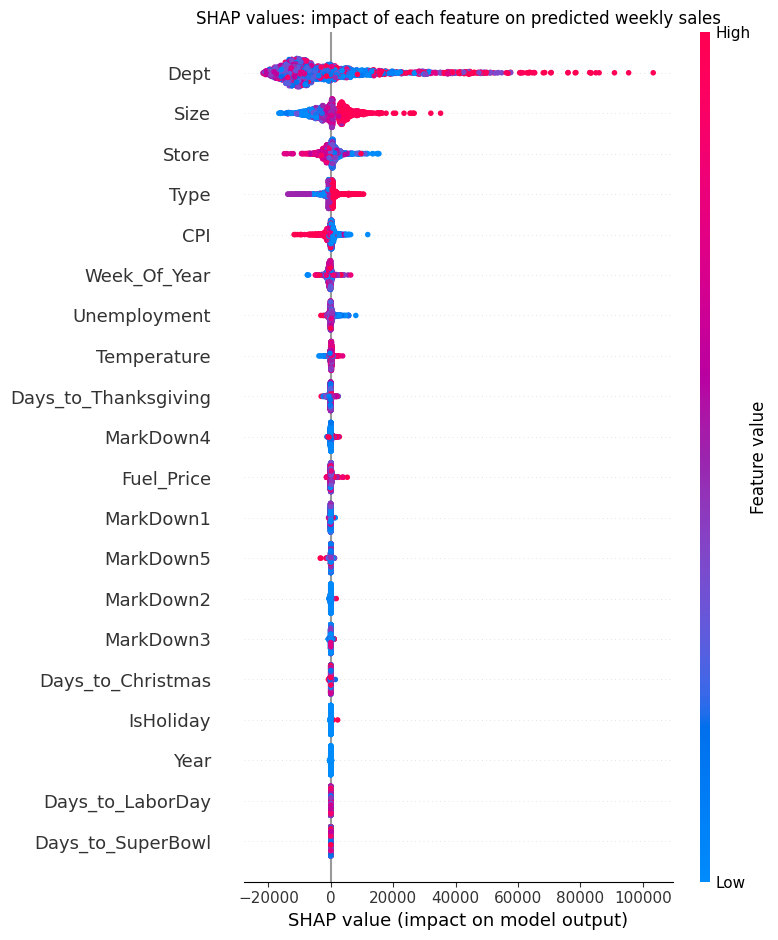

In [94]:
import shap
import matplotlib.pyplot as plt

X_val_sample = X_val.sample(2000, random_state=42)
X_val_sample_transformed = pd.DataFrame(
    XGB_pipeline.named_steps["Preprocessing"].transform(X_val_sample),
    columns=feature_names,
)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_val_sample_transformed)

shap.summary_plot(shap_values, X_val_sample_transformed, show=False)
plt.title("SHAP values: impact of each feature on predicted weekly sales")
plt.tight_layout()
plt.show()

**Reading the plots:**

* **Dept, Size, Store and Type dominate.** *What* is sold and *where* explains most of the sales level: larger stores (red on `Size`) and Type A stores push predictions up, and a handful of departments produce the very large positive SHAP values (up to +$100k).
* **CPI** has a clear negative effect (high CPI → lower predictions). CPI is regional and almost constant per store, so the model most likely uses it as a *store location proxy*, not as an economic driver. It should not be read as causal.
* **Seasonality** is carried by `Week_Of_Year` and `Days_to_Thanksgiving`. `Days_to_SuperBowl` and `Days_to_LaborDay` have **zero importance**: they could be dropped without loss.
* Markdowns, Temperature and Fuel_Price have a small impact, consistent with the correlation matrix from the EDA.

**Important caveat on the validation set:** the 2012 data stops on **2012-10-26**, so the validation set contains **no Thanksgiving and no Christmas weeks**, the biggest peaks of the year. That explains why the holiday-week error (2,857) is close to the non-holiday error (2,726): the hardest weeks were never tested. The WMAE above is therefore optimistic compared to what Kaggle would measure on the test set (Nov 2012 → Jul 2013, which includes Thanksgiving and Christmas 2012).

In [95]:
import joblib

joblib.dump(XGB_pipeline, "walmart_xgb_model.pkl")
print("Model saved!")

Model saved!


Submitting results:

In [96]:
import pandas as pd
import numpy as np
import joblib

test = pd.read_csv("./Data/test.csv")
features = pd.read_csv("./Data/features.csv")
stores = pd.read_csv("./Data/stores.csv")

feature_store_merged = features.merge(stores, how="inner", on="Store")
test_final_merged = test.merge(feature_store_merged, how="inner", on=["Store", "Date", "IsHoliday"])
test_final_merged = test_final_merged.sort_values(by=["Store", "Dept", "Date"])
test_final_merged = test_final_merged.reset_index(drop=True)

# Kaggle Id format: Store_Dept_Date, built from the data itself so rows can never be misaligned
ids = (test_final_merged["Store"].astype(str) + "_"
       + test_final_merged["Dept"].astype(str) + "_"
       + test_final_merged["Date"])

test_final_merged["Date"] = pd.to_datetime(test_final_merged["Date"])
test_final_merged["Year"] = test_final_merged["Date"].dt.year
test_final_merged["Week_Of_Year"] = test_final_merged["Date"].dt.isocalendar().week.astype(int)

test_final_merged = add_days_to_holidays(test_final_merged)

markdown_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]
test_final_merged[markdown_cols] = test_final_merged[markdown_cols].fillna(0)

test_final_merged["IsHoliday"] = test_final_merged["IsHoliday"].astype(int)

test_final_merged = test_final_merged.drop(columns=["Date"])

XGB_pipeline = joblib.load("walmart_xgb_model.pkl")
XGB_pipeline.named_steps["Model"].set_params(device="cpu")
predictions = XGB_pipeline.predict(test_final_merged)

submission = pd.DataFrame({"Id": ids, "Weekly_Sales": predictions})

# sanity checks against Kaggle's expected format
sample = pd.read_csv("./Data/sampleSubmission.csv")
assert len(submission) == len(sample) and set(submission["Id"]) == set(sample["Id"])

submission.to_csv("walmart_submission.csv", index=False)
print("Submission saved to walmart_submission.csv")
print(submission.head())

Submission saved to walmart_submission.csv
               Id  Weekly_Sales
0  1_1_2012-11-02  35701.605469
1  1_1_2012-11-09  17792.054688
2  1_1_2012-11-16  17841.896484
3  1_1_2012-11-23  17910.480469
4  1_1_2012-11-30  24532.037109
